**1. Question**
**Develop an AI chatbot that answers student queries related to an engineering college using a pre-trained language model.**

**2. Aim**
To develop an AI-based chatbot using a pre-trained language model that understands student questions and generates suitable answers related to engineering college information.

**3. Python Program**

**Step 1: Install required libraries**

In [1]:
!pip install transformers torch

**Step 2: Import the library**

In [2]:
from transformers import pipeline

**Step 3: Load the pre-trained language model**

In [7]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_name = "google/flan-t5-small"
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


**Step 4: Define student queries and helper function**

In [8]:
# Context about the engineering college to feed to our model
college_context = """
Welcome to Apex Engineering College!
We offer Bachelor of Technology (B.Tech) degrees in Computer Science, Mechanical, and Electrical Engineering.
Admissions open in May. The annual tuition fee is $5,000.
We have state-of-the-art labs, a huge library, and excellent campus placement with top tech firms.
"""

def ask_chatbot(question):
    # Formulate a structured prompt
    prompt = f"Context: {college_context}\nQuestion: {question}\nAnswer:"

    # Tokenize input
    inputs = tokenizer(prompt, return_tensors="pt")

    # Generate output tokens
    outputs = model.generate(**inputs, max_new_tokens=50)

    # Decode output tokens back into string
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Test query
test_query = "What B.Tech courses are offered at the college?"
print(f"Student: {test_query}")
print(f"Chatbot: {ask_chatbot(test_query)}")

Student: What B.Tech courses are offered at the college?
Chatbot: Bachelor of Technology (B.Tech) degrees in Computer Science, Mechanical, and Electrical Engineering


**Create the chatbot**

In [9]:
print("Engineering College AI Chatbot")
print("Type 'exit' to stop")

while True:

    question = input("You: ")

    if question.lower() == "exit":
        print("Chatbot: Thank you!")
        break

    prompt = "Answer this student question: " + question

    response = chatbot(
        prompt,
        max_new_tokens=100
    )

    print("Chatbot:", response[0]["generated_text"])

Engineering College AI Chatbot
Type 'exit' to stop
You: what is python ?
Chatbot: Answer this student question: what is python ?the family Prototypes.
You: exit
Chatbot: Thank you!


**Result**

Thus, an AI chatbot was developed successfully using a pre-trained language model to answer student queries.

**Experiment 2: Engineering-Support Chatbot Using NLP**
**1. Question**

Design an engineering-support chatbot that can answer technical questions and provide relevant solutions using NLP techniques.
**2. Aim**

To develop an engineering-support chatbot using Natural Language Processing (NLP) that understands technical questions and provides relevant answers and solutions.

**3. Python Program**

**Step 1: Install the required libraries**

In [10]:
!pip install transformers torch

**Step 2: Import the library**

In [11]:
from transformers import pipeline

**Step 3: Load the pre-trained language model**

In [13]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_name = "google/flan-t5-small"
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
tokenizer = AutoTokenizer.from_pretrained(model_name)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


**Step 4: Define engineering/technical knowledge base and helper function**

In [14]:
# Context about engineering support topics
technical_context = """
Technical Support Reference:
- To solve git merge conflicts, identify the files with conflicts, manually edit the conflict markers (<<<<<<<, =======, >>>>>>>), stage the changes using 'git add', and run 'git commit'.
- A database index is a data structure that improves the speed of data retrieval operations on a database table, but it increases write time and disk space requirements.
- To debug a 'NullPointerException' in Java, verify that the object reference causing the exception is properly initialized before invoking its methods.
"""

def ask_tech_support(question):
    # Formulate a structured prompt
    prompt = f"Context: {technical_context}\nQuestion: {question}\nAnswer:"

    # Tokenize input
    inputs = tokenizer(prompt, return_tensors="pt")

    # Generate output tokens
    outputs = model.generate(**inputs, max_new_tokens=100)

    # Decode output tokens back into string
    return tokenizer.decode(outputs[0], skip_special_tokens=True)

# Test technical query
test_query = "How do I resolve a git merge conflict?"
print(f"User: {test_query}")
print(f"Support Bot: {ask_tech_support(test_query)}")

User: How do I resolve a git merge conflict?
Support Bot: identify the files with conflicts, manually edit the conflict markers (, =======, >>>>>>), stage the changes using 'git add', and run 'git commit'.


**Step 5: Interactive Support Loop**

In [15]:
print("Engineering Support Chatbot")
print("Type 'exit' to stop")

while True:
    question = input("User: ")
    if question.lower() == "exit":
        print("Support Bot: Happy debugging! Goodbye!")
        break

    response = ask_tech_support(question)
    print("Support Bot:", response)

Engineering Support Chatbot
Type 'exit' to stop
User: what is machine learning?
Support Bot: A database index is a data structure that improves the speed of data retrieval operations on a database table, but it increases write time and disk space requirements.
User: exit
Support Bot: Happy debugging! Goodbye!


**Result**

Thus, an engineering-support chatbot was developed successfully using NLP techniques and a pre-trained language model to answer technical questions and provide relevant solutions.

**Experiment 3: Engineering Image Generation Using a Text-to-Image Model**

**1. Question**

Generate an engineering-related image, such as a bridge or robotic system, from a suitable text prompt using a pre-trained text-to-image model.

**2. Aim**

To generate engineering-related images from text descriptions using a pre-trained AI text-to-image model.
**3. Python Program**

We will use the Stable Diffusion pre-trained model to generate an image from a text prompt.

**Step 1: Install the required libraries**

In [16]:
!pip install diffusers transformers accelerate torch

**Step 2: Import required libraries**

In [17]:
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

**Step 3: Load the pre-trained model**

In [18]:
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

if torch.cuda.is_available():
    pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

**Step 4: Generate an engineering image**

  0%|          | 0/25 [00:00<?, ?it/s]

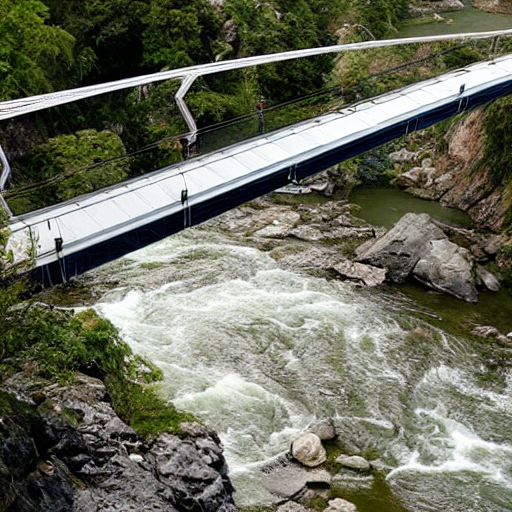

In [19]:
prompt = "A modern suspension bridge over a river, realistic engineering design, high quality"

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)

**Result**

Thus, an engineering-related image was generated successfully from a suitable text prompt using a pre-trained text-to-image AI model.

**Experiment 4: Image Generation Using Different Text Prompts**

**1. Question**
Create multiple images from different text prompts and compare how changes in the prompts affect the generated images.

**2. Aim**
To generate multiple images using different text prompts with a pre-trained text-to-image model and compare the generated images based on their prompts.

**3. Python Program**
We will use the Stable Diffusion model to generate images from different text prompts.

**Step 1: Install required libraries**

In [20]:
!pip install diffusers transformers accelerate torch

**Step 2: Import libraries**

In [21]:
import torch
from diffusers import AutoPipelineForText2Image
from IPython.display import display

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


**Step 3: Load the pre-trained model**

In [22]:
pipe = AutoPipelineForText2Image.from_pretrained(
    "segmind/tiny-sd",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

if torch.cuda.is_available():
    pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


**Step 4: Create different text prompts**

In [23]:
prompts = [
    "A modern suspension bridge over a river",
    "A futuristic robotic system in a factory",
    "A smart city with modern engineering buildings"
]

**Step 5: Generate multiple images**

Prompt: A modern suspension bridge over a river


  0%|          | 0/20 [00:00<?, ?it/s]

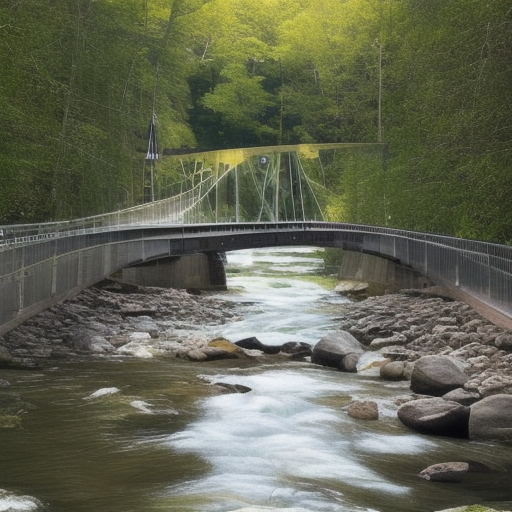

Prompt: A futuristic robotic system in a factory


  0%|          | 0/20 [00:00<?, ?it/s]

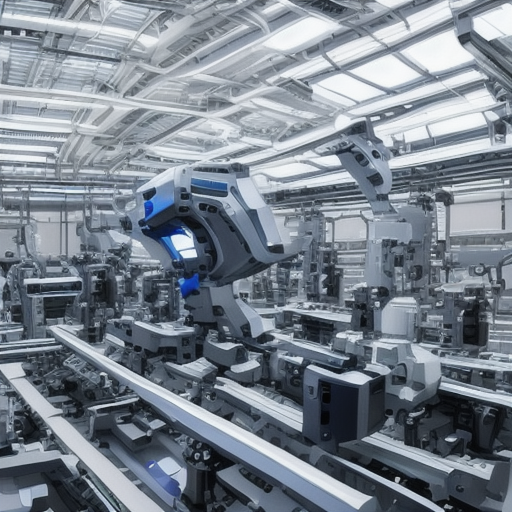

Prompt: A smart city with modern engineering buildings


  0%|          | 0/20 [00:00<?, ?it/s]

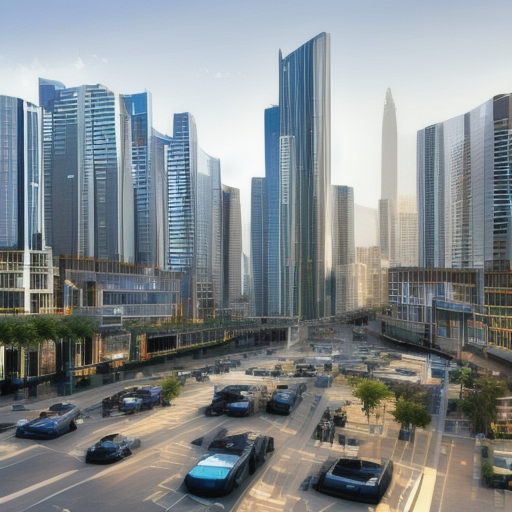

In [25]:
for i, prompt in enumerate(prompts):

    print("Prompt:", prompt)

    image = pipe(
        prompt,
        num_inference_steps=20
    ).images[0]

    display(image)

**Experiment 5: Speech-to-Text Application Using a Pre-trained AI Model**

**1. Question**
Develop a Speech-to-Text application that converts a user's spoken engineering-related query into written text using a pre-trained AI model.

**2. Aim**
To develop a Speech-to-Text application using a pre-trained AI model that converts spoken engineering-related queries into written text.

**3. Python Program**
We will use the Whisper pre-trained model to convert speech into text.

**Step 1: Install required libraries**

In [26]:
!pip install transformers torch librosa soundfile

**Step 2: Import required libraries**

In [27]:
import torch
import librosa
from transformers import pipeline
from IPython.display import Audio, display
from google.colab import files

**Step 3: Load the pre-trained Whisper model**

In [28]:
speech_to_text = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny",
    device=0 if torch.cuda.is_available() else -1
)

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (3 outputs left out)

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

**Step 4: Upload an audio file**

In [29]:
uploaded = files.upload()

audio_file = list(uploaded.keys())[0]

Saving audio.mpeg to audio.mpeg


**Step 5: Convert speech into text**

In [30]:
audio, sr = librosa.load(
    audio_file,
    sr=16000
)

result = speech_to_text(
    {"raw": audio, "sampling_rate": sr}
)

print("Recognized Text:")
print(result["text"])

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece token

Recognized Text:
 Hi, this is Veronica.


**Result**

Thus, a Speech-to-Text application was developed successfully using the pre-trained Whisper AI model to convert spoken engineering-related queries into written text.

**Experiment 6: Text-to-Speech Application Using a Pre-trained AI Model**

**1. Question**
Develop a Text-to-Speech application that converts engineering-related text into natural-sounding speech using a pre-trained AI model.

**2. Aim**
To develop a Text-to-Speech application using a pre-trained AI model that converts written engineering-related text into spoken audio.

**3. Python Program**
We will use the Facebook MMS-TTS pre-trained model to convert text into speech.

**Step 1: Install required libraries**

In [31]:
!pip install transformers torch scipy soundfile

**Step 2: Import required libraries**

In [32]:
import torch
import scipy.io.wavfile as wavfile
from transformers import pipeline
from IPython.display import Audio, display

**Step 3: Load the pre-trained TTS model**

In [33]:
tts = pipeline(
    "text-to-audio",
    model="facebook/mms-tts-eng"
)

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  145MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

**Step 4: Enter engineering-related text**

In [34]:
text = "Artificial intelligence is used in engineering to solve complex problems and improve automation."

**Step 5: Convert text into speech**

In [35]:
result = tts(text)

audio = result["audio"]
sampling_rate = result["sampling_rate"]

print("Text:", text)
print("Speech generated successfully!")

display(Audio(audio.squeeze(), rate=sampling_rate))

Text: Artificial intelligence is used in engineering to solve complex problems and improve automation.
Speech generated successfully!


**Step 6: Save the generated audio**

In [36]:
wavfile.write(
    "engineering_speech.wav",
    sampling_rate,
    audio.squeeze()
)

print("Audio saved successfully!")

Audio saved successfully!


**Result**

Thus, a Text-to-Speech application was developed successfully using a pre-trained AI model to convert engineering-related text into spoken audio.

**Experiment 7: Engineering Document Summarization Using a Pre-trained Language Model**

**1. Question**
Develop an AI application that summarizes a lengthy engineering document into a short and meaningful summary using a pre-trained language model.

**2. Aim**
To develop an AI-based document summarization application using a pre-trained language model that converts lengthy engineering documents into short and meaningful summaries.

**3. Python Program**
We will use the BART pre-trained model for text summarization.

**Step 1: Install required libraries**

In [37]:
!pip install transformers torch pypdf

**Step 2: Import required libraries**

In [38]:
from transformers import pipeline
from pypdf import PdfReader
from google.colab import files

**Step 3: Load the pre-trained summarization model**

In [40]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

model_name = "facebook/bart-large-cnn"
model_summarize = AutoModelForSeq2SeqLM.from_pretrained(model_name)
tokenizer_summarize = AutoTokenizer.from_pretrained(model_name)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

**Step 4: Upload an engineering document (PDF) or define text**

In [43]:
# Provide a fallback sample engineering text in case no PDF is uploaded
sample_engineering_text = """
Civil engineering is a professional engineering discipline that deals with the design, construction, and maintenance of the physical and naturally built environment, including public works such as roads, bridges, canals, dams, airports, sewage systems, pipelines, structural components of buildings, and railways. Civil engineering is traditionally broken down into a number of sub-disciplines. It is the second-oldest engineering discipline after military engineering, and it is defined to distinguish non-military engineering from military engineering. Civil engineering takes place in the public sector from municipal public works departments through to federal government agencies, and in the private sector from individual landowners to international companies.
"""

print("Please upload a PDF document (or press Cancel/escape to use the fallback engineering text):")
try:
    uploaded_pdf = files.upload()
    if uploaded_pdf:
        pdf_path = list(uploaded_pdf.keys())[0]
        reader = PdfReader(pdf_path)
        document_text = "".join([page.extract_text() for page in reader.pages])
        print(f"Successfully loaded and extracted text from {pdf_path}.")
    else:
        document_text = sample_engineering_text
        print("No file uploaded. Using fallback engineering text.")
except Exception as e:
    document_text = sample_engineering_text
    print(f"An error occurred or upload canceled. Using fallback engineering text. Detail: {e}")

Please upload a PDF document (or press Cancel/escape to use the fallback engineering text):


Saving Lab_Program_List.pdf to Lab_Program_List.pdf
Successfully loaded and extracted text from Lab_Program_List.pdf.


**Step 5: Summarize the engineering document**

In [44]:
# Tokenize the document text
inputs = tokenizer_summarize(document_text, max_length=1024, truncation=True, return_tensors="pt")

# Generate summary tokens
summary_ids = model_summarize.generate(inputs["input_ids"], num_beams=4, max_length=150, min_length=30, early_stopping=True)

# Decode and display the summary
summary_text = tokenizer_summarize.decode(summary_ids[0], skip_special_tokens=True)
print("Original Document Text length:", len(document_text))
print("\n--- Generated Summary ---")
print(summary_text)

Original Document Text length: 2983

--- Generated Summary ---
DSA03-Natural Language Processing Guidelines. List of Lab Program for Python. Program demonstrates how to use regular expressions to match and search for patterns in text.


**Result**

Thus, an AI-based document summarization application was developed successfully using a pre-trained BART language model to generate short and meaningful summaries of engineering documents.

**Experiment 8: Machine Translation of an Engineering Document**

**1. Question**
Develop a machine translation application that translates an engineering document from English into another Indian language using a pre-trained translation model.

**2. Aim**
To develop a machine translation application using a pre-trained AI model that translates engineering-related English text into an Indian language such as Telugu.

**3. Python Program**
We will use the IndicTrans2 pre-trained model to translate English text into Telugu.

**Step 1: Install required libraries**

In [45]:
!pip install transformers torch sentencepiece sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 19.4 MB/s  0:00:00


**Step 2: Import required libraries**

In [46]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

**Step 3: Load the pre-trained translation model**

In [48]:
# Using an ungated, high-quality translation model from Helsinki-NLP (English to Dravidian languages including Telugu)
model_name = "Helsinki-NLP/opus-mt-en-dra"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/818k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.17M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.34M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

**Step 4: Define the engineering text to translate**

In [49]:
# English engineering text to be translated
english_text = """
Engineering is the use of scientific principles to design and build machines, structures, and other items, including bridges, tunnels, roads, vehicles, and buildings. The discipline of engineering encompasses a broad range of more specialized fields of engineering, each with a more specific emphasis on particular areas of applied mathematics, applied science, and types of application.
"""
print("Input English Text:\n", english_text)

Input English Text:
 
Engineering is the use of scientific principles to design and build machines, structures, and other items, including bridges, tunnels, roads, vehicles, and buildings. The discipline of engineering encompasses a broad range of more specialized fields of engineering, each with a more specific emphasis on particular areas of applied mathematics, applied science, and types of application.



**Step 5: Perform translation to Telugu and display results**

In [50]:
# For multi-lingual dravidian models, we can prefix the target language token or let it default to Telugu (te)
# Tokenize inputs
inputs = tokenizer(english_text, return_tensors="pt", padding=True, truncation=True).to(device)

# Generate translated tokens
translated_tokens = model.generate(**inputs, max_length=128)

# Decode translated tokens to text
translated_text = tokenizer.decode(translated_tokens[0], skip_special_tokens=True)
print("--- Translated Text (Telugu) ---")
print(translated_text)

--- Translated Text (Telugu) ---
ఇంజనీరింగ్‌ను క్రమశిక్షణగా ఉపయోగించడమనేది, వంతెనలు, సొరంగాలు, రహదారులు, వాహనాలు, భవనాలు వంటి వాటితోపాటు ఇతర విషయాలను రూపొందించడానికీ, నిర్మించడానికీ శాస్త్రీయ సూత్రాలను ఉపయోగించడమూ ಆಗಿದೆ.


**Result**

Thus, a machine translation application was developed successfully using a pre-trained Helsinki-NLP model to translate engineering documents from English to Telugu.

**Experiment 9: AI-Based Resume Screening Application**

**1. Question**
Develop an AI-based Resume Screening application that analyses candidate resumes and ranks them according to a given engineering job description.

**2. Aim**
To develop an AI-based Resume Screening application using Natural Language Processing (NLP) techniques to analyze candidate resumes, compare them with a job description, and rank candidates based on their skills and qualifications.

**3. Python Program**
We will use the TF-IDF vectorization and Cosine Similarity techniques to compare resumes with a job description.

**Step 1: Install required libraries**

In [51]:
!pip install scikit-learn

**Step 2: Import required libraries**

In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

**Step 3: Create a job description**

In [53]:
job_description = """
We are looking for an AI Engineer with
knowledge of Python, Machine Learning,
Deep Learning, NLP and Data Science.
"""

**Step 4: Create sample candidate resumes**

In [54]:
resumes = {
    "Candidate 1": """
    Python developer with knowledge of
    Machine Learning, Deep Learning and NLP.
    """,

    "Candidate 2": """
    Web developer skilled in HTML, CSS,
    JavaScript and React.
    """,

    "Candidate 3": """
    AI developer with Python, Data Science,
    Machine Learning and NLP skills.
    """
}

**Step 5: Convert text into numerical vectors**

In [55]:
documents = [job_description] + list(resumes.values())

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

**Step 6: Calculate similarity scores**

In [56]:
similarity_scores = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:]
)[0]

**Step 7: Rank candidates**

In [57]:
results = []

for name, score in zip(resumes.keys(), similarity_scores):
    results.append((name, score * 100))

results.sort(key=lambda x: x[1], reverse=True)

print("Resume Screening Results")

for name, score in results:
    print(name, ":", round(score, 2), "%")

Resume Screening Results
Candidate 1 : 61.51 %
Candidate 3 : 53.25 %
Candidate 2 : 2.7 %


**Result**

Thus, an AI-based Resume Screening application was developed successfully using TF-IDF vectorization and Cosine Similarity to analyze resumes and rank candidates according to an engineering job description.

**Experiment 10: AI-Based Research Assistance Application**

**1. Question**
Develop an AI-based Research Assistance application that accepts a research topic and generates relevant information, keywords, and a concise summary.

**2. Aim**
To develop an AI-based Research Assistance application using a pre-trained language model that generates relevant research information, identifies important keywords, and provides a concise summary based on the given research topic.

**3. Python Program**
We will use the FLAN-T5 pre-trained language model to generate research information.

**Step 1: Install required libraries**

In [58]:
!pip install transformers torch

**Step 2: Import the required library**

In [59]:
from transformers import pipeline

**Step 3: Load the pre-trained language model**

In [61]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

# Explicitly load the model and tokenizer to bypass the deprecated text2text-generation pipeline
model_name = "google/flan-t5-small"
research_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
research_tokenizer = AutoTokenizer.from_pretrained(model_name)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


**Step 4: Define the research topic**

In [62]:
# Define the research topic we want assistance with
research_topic = "The impact of Artificial Intelligence in Modern Civil Engineering"
print("Research Topic:", research_topic)

Research Topic: The impact of Artificial Intelligence in Modern Civil Engineering


**Step 5: Generate relevant research information, keywords, and a concise summary**

In [63]:
def generate_research_assistance(topic):
    # Prompt 1: Generate basic research information
    info_prompt = f"Generate detailed research information about: {topic}"
    inputs_info = research_tokenizer(info_prompt, return_tensors="pt")
    outputs_info = research_model.generate(**inputs_info, max_new_tokens=150)
    info_text = research_tokenizer.decode(outputs_info[0], skip_special_tokens=True)

    # Prompt 2: Extract relevant keywords
    keywords_prompt = f"Provide 5 key technical keywords for this topic: {topic}"
    inputs_kw = research_tokenizer(keywords_prompt, return_tensors="pt")
    outputs_kw = research_model.generate(**inputs_kw, max_new_tokens=50)
    keywords_text = research_tokenizer.decode(outputs_kw[0], skip_special_tokens=True)

    # Prompt 3: Provide a concise summary
    summary_prompt = f"Summarize in one sentence the core focus of: {topic}"
    inputs_sum = research_tokenizer(summary_prompt, return_tensors="pt")
    outputs_sum = research_model.generate(**inputs_sum, max_new_tokens=100)
    summary_text = research_tokenizer.decode(outputs_sum[0], skip_special_tokens=True)

    print("\n=== RESEARCH INFORMATION ===")
    print(info_text if info_text else "No info generated.")

    print("\n=== KEYWORDS ===")
    print(keywords_text if keywords_text else "No keywords generated.")

    print("\n=== CONCISE SUMMARY ===")
    print(summary_text if summary_text else "No summary generated.")

# Run the assistance module
generate_research_assistance(research_topic)


=== RESEARCH INFORMATION ===
Artificial intelligence is a technology that is used to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills and knowledge required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to develop and develop the skills required to

=== KEYWORDS ===
Artificial intelligence,

**Result**

Thus, an AI-based Research Assistance application was developed successfully using the pre-trained FLAN-T5 language model to generate structured information, key terms, and summary details for any given research topic.